<a href="https://colab.research.google.com/github/rawanmd/segmentation_coverless_steg/blob/main/segmentation_coverless_steg_sam.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [12]:
from textwrap import indent
from google.colab import drive

import os
import glob
import json
import time
import math
import numpy as np

import torchvision
import torchvision.transforms.functional as F
import cv2
import matplotlib.pyplot as plt
import torch

In [13]:
INVERTED_INDEX_FILEPATH : str = "/content/drive/MyDrive/coco_dataset/sam_inverted_index.json"

## Connect to Drive

In [14]:
from google.colab import drive

# Mount Drive
drive.mount('/content/drive')

# Dataset root
dataset_dir = "/content/drive/MyDrive/coco_dataset"
os.makedirs(dataset_dir, exist_ok=True)

# Move into dataset folder
%cd $dataset_dir

# Create desired folders
os.makedirs("annotations", exist_ok=True)
os.makedirs("train", exist_ok=True)
os.makedirs("val", exist_ok=True)

# ==========================
# 1. ANNOTATIONS
# ==========================
# !wget -c http://images.cocodataset.org/annotations/annotations_trainval2017.zip

# !unzip -q annotations_trainval2017.zip
# !rm annotations_trainval2017.zip

# # ==========================
# # 2. VALIDATION IMAGES
# # ==========================
# !wget -c http://images.cocodataset.org/zips/val2017.zip

# !unzip -q val2017.zip
# !rm val2017.zip

# # Move images into val/
# !mv val2017/* val/
# !rmdir val2017

# ==========================
# 3. TRAIN IMAGES
# ==========================
# !wget -c http://images.cocodataset.org/zips/train2017.zip

# !unzip -q train2017.zip
# !rm train2017.zip

# # Move images into train/
# !mv train2017/* train/
# !rmdir train2017

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
/content/drive/.shortcut-targets-by-id/1dinARnYQo63aQ4wGOpso2i0udPTc5ztG/coco_dataset


## Import SAM

In [15]:
!pip install git+https://github.com/facebookresearch/segment-anything.git
!pip install opencv-python pycocotools matplotlib
!pip install torch torchvision

import torch
import cv2
import matplotlib.pyplot as plt

!wget https://dl.fbaipublicfiles.com/segment_anything/sam_vit_b_01ec64.pth

from segment_anything import sam_model_registry, SamAutomaticMaskGenerator

  Cloning https://github.com/facebookresearch/segment-anything.git to /tmp/pip-req-build-1zj_4qqs
  Running command git clone --filter=blob:none --quiet https://github.com/facebookresearch/segment-anything.git /tmp/pip-req-build-1zj_4qqs
  Resolved https://github.com/facebookresearch/segment-anything.git to commit dca509fe793f601edb92606367a655c15ac00fdf
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for segment_anything: filename=segment_anything-1.0-py3-none-any.whl size=36637 sha256=af9fa8418e5b5292edef63407bf2d38ee7945f0bac9e9ce793ca8bc55d72e775
  Stored in directory: /tmp/pip-ephem-wheel-cache-gn7vqqcb/wheels/5d/7b/4a/c7fda89f2e27647dd0816f51ea103992b1b6f0f53ad234895c
Successfully built segment_anything
--2026-11-26 11:38:21--  https://dl.fbaipublicfiles.com/segment_anything/sam_vit_b_01ec64.pth
Resolving dl.fbaipublicfiles.com (dl.fbaipublicfiles.com)... 65.9.168.62, 65.9.168.8

In [16]:
MODEL_TYPE = "vit_b"
CHECKPOINT = "sam_vit_b_01ec64.pth"

device = "cuda" if torch.cuda.is_available() else "cpu"

sam = sam_model_registry[MODEL_TYPE](checkpoint=CHECKPOINT)
sam.to(device=device)

mask_generator = SamAutomaticMaskGenerator(sam)

## Functions

In [17]:
def extract_masks(image_path):

  image = cv2.imread(image_path)
  image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
  masks = mask_generator.generate(image)

  binary_seq = ""
  pix = 0

  for i in range(len(masks) - 1):
    bbox1 = masks[i]['bbox']
    x1, y1 = bbox1[:2]

    bbox2 = masks[i+1]['bbox']
    x2, y2 = bbox2[:2]

    d_squared = (x2 - x1)**2 + (y2 - y1)**2
    d = math.sqrt(d_squared)

    if(d <= 300):
      binary_seq += '0'
    else:
      binary_seq += '1'

  r, _, _ = cv2.split(image)
  pix = np.mean(r)

  return binary_seq, pix



def get_image_paths(dir):
  image_paths = sorted(glob.glob(os.path.join(dir, '*.jpg')))
  print(f"Found {len(image_paths)} images.")
  return image_paths



# def build_index(image_paths):
#   index = {}
#   image_paths = get_image_paths(image_paths)
#   print(f"image_paths: {image_paths}")
#   for image_path in image_paths:
#     # call segmentation model
#     binary_seq, pix = extract_masks(image_path)

#     if binary_seq is None or binary_seq == "":
#       continue

#     if binary_seq not in index:
#       index[binary_seq] = []

#     index[binary_seq].append({"image path": image_path,
#                               "pix": pix})

#     with open(str(dataset_dir)+"/inverted_index.json", "w") as f:
#       json.dump(index, f, indent=4)

#   return index

In [18]:
def build_index(image_dir):
  image_paths = get_image_paths(image_dir)

  if os.path.exists(INVERTED_INDEX_FILEPATH):
    print(f"Loading existing index from:\n{INVERTED_INDEX_FILEPATH}")

    with open(INVERTED_INDEX_FILEPATH, "r") as f:
      index = json.load(f)

    processed_images = set()

    for binary_seq, images in index.items():
      for image_info in images:
        processed_images.add(image_info["image path"])

    print(f"Already processed: {len(processed_images)} images")

  else:
    print("No existing index found. Starting from scratch.")
    index = {}
    processed_images = set()

  remaining_images = [
    image_path
    for image_path in image_paths
    if image_path not in processed_images
  ]

  print(f"Total images: {len(image_paths)}")
  print(f"Remaining images: {len(remaining_images)}")

  for count, image_path in enumerate(remaining_images, start=1):

    try:
      binary_seq, pix = extract_masks(image_path)

      if binary_seq is None or binary_seq == "":
        print(f"[{count}/{len(remaining_images)}] "
              f"Skipped: {image_path}")
        continue

      if binary_seq not in index:
        index[binary_seq] = []

      index[binary_seq].append({
        "image path": image_path,
        "pix": pix
      })

      temp_filepath = INVERTED_INDEX_FILEPATH + ".tmp"

      with open(temp_filepath, "w") as f:
        json.dump(index, f, indent=4)

      os.replace(temp_filepath, INVERTED_INDEX_FILEPATH)

      print(
        f"[{count}/{len(remaining_images)}] "
        f"Processed: {os.path.basename(image_path)} "
        f"| sequence length: {len(binary_seq)}"
      )

    except Exception as e:
      print(f"\nERROR processing: {image_path}")
      print(f"Error: {e}")
      print("Skipping this image and continuing...")
      continue

  processed_images = set()

  for binary_seq, images in index.items():
    for image_info in images:
      processed_images.add(image_info["image path"])

  print("\n==============================")
  print("Index building finished/stopped")
  print("==============================")
  print(f"Total dataset images: {len(image_paths)}")
  print(f"Images in index:      {len(processed_images)}")
  print(f"Remaining images:     {len(image_paths) - len(processed_images)}")
  print(f"Number of keys:       {len(index)}")

  return index

In [19]:
def match_msg_to_images(binary_msg: str, window_size: int, prefix_maps: dict) -> (list[str], int, int):
  """
  finds the optimal window size and matches images in the inverted index with the binary representation of the message.

  Searches using an index with variable-length keys.The scan window is sized to the longest key in the index, ensuring
  that all possible key matches can be detected.

  Args:
    binary_msg (str): Binary representation of the secret message.
    window_size (int): Maximum window size available in the inverted index.
    inverted_index (dict): contains all binary_sequences extracted from the images in the dataset and the images themselves.

  Returns:
    image_paths (list[str]): list of file paths of images that matched the binary message. Returns [] if matching failed.
    window_size (int): Final window size that successfully matched the entire message. Returns -1 if matching failed.
    num_zeros (int): the number of trailing zeroes that were added to the last chunk match the window size or -1 if matching failed.
  """

  for current_window_size in range(window_size, 0, -1):
    image_paths = []
    success = True
    pix_so_far = 0

    print(f"\nTrying window size: {current_window_size}")

    for i in range(0, len(binary_msg), current_window_size):

      chunk = binary_msg[i:i + current_window_size]
      num_zeros = 0

      # add trailing zeros to last chunk
      if len(chunk) < current_window_size:
          num_zeros = current_window_size - len(chunk)
          chunk = chunk.ljust(current_window_size, '0')

      print(f"chunk: {chunk}")

      keys = prefix_maps[current_window_size].get(chunk)

      if keys == None:
        print(f"No match for {chunk}")
        success = False
        break

      # valid_keys = [
      #   key for key in keys
      #   if key["pix"] > pix_so_far
      # ]

      # if not valid_keys:
      #     print(f"No valid image for {chunk} after pix {pix_so_far}")
      #     success = False
      #     break

      # key = min(valid_keys, key=lambda x: x["pix"])

      image_paths.append(keys[0]['image path'])
      # pix_so_far = key['pix']
      print(f"key: {keys[0]['image path']}")

    if success:
      print(f"\n\nimage paths: {image_paths}")
      print(f"Final window size: {current_window_size}")
      return image_paths, current_window_size, num_zeros

  return [], -1, -1



def build_prefix_maps(inverted_index):

  prefix_maps = {}

  for binary_seq, images in inverted_index.items():

      seq_len = len(binary_seq)

      for prefix_len in range(1, seq_len + 1):

          prefix = binary_seq[:prefix_len]

          if prefix_len not in prefix_maps:
              prefix_maps[prefix_len] = {}

          if prefix not in prefix_maps[prefix_len]:
              prefix_maps[prefix_len][prefix] = []

          prefix_maps[prefix_len][prefix].extend(images)

  return prefix_maps

In [20]:
def sort_pix(image_paths):
  res = []

  for path in image_paths:
    image = cv2.imread(path)
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    r, _, _ = cv2.split(image)

    pix = (int) (np.mean(r))

    res.append((path, pix))

  res.sort(key=lambda x: x[1])
  return [path for path, _ in res]



def extraxt_bin_msg(image_paths, window_size, num_zeros):
  bin_msg = ''
  image_paths = sort_pix(image_paths)

  for image_path in image_paths:
    # call segmentation model
    binary_seq, _ = extract_masks(image_path)

    if binary_seq is None:
      continue

    bin_msg += binary_seq[:window_size]

  if num_zeros > 0:
    num_zeros *= -1
    bin_msg[:num_zeros]

  return binary_msg

In [21]:
def string_to_binary(text: str) -> str:
    """
    Converts a string into a space-separated binary representation.
    """
    return ''.join(format(ord(char), '08b') for char in text)

def binary_to_string(binary_text: str) -> str:
    """
    Converts a space-separated binary string back into text.
    """
    return ''.join(
        chr(int(binary_text[i:i+8], 2))
        for i in range(0, len(binary_text), 8)
    )

## Embedding (Matching)

In [22]:
start = time.perf_counter()

PATH = "/content/drive/MyDrive/coco_dataset/train2017"

secret_msg = "HelloWorld"

binary_msg = string_to_binary(secret_msg)

# build index if not already there
# inverted_index = build_index(PATH)

# load index if it exists
with open(INVERTED_INDEX_FILEPATH, "r") as f:
  inverted_index = json.load(f)

inverted_index = build_prefix_maps(inverted_index)

In [23]:
window_size = max(inverted_index.keys())
print(f"Max window size in index: {window_size}")

images, w_size, num_zeros = match_msg_to_images(binary_msg, window_size, inverted_index)
# images, w_size, num_zeros = match_msg_to_images('1101111', 4, inverted_index)  # just an example for tracing

end = time.perf_counter()

Max window size in index: 371

Trying window size: 371
chunk: 01001000011001010110110001101100011011110101011101101111011100100110110001100100000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000
No match for 01001000011001010110110001101100011011110101011101101111011100100110110001100100000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000

Trying window size: 370
chunk: 01001000011001010110110001101100011011110101011101101111011100100110110001100100000000000000000000000000000000000000000000000000000000000000000000000

In [24]:
print(f"Keys: {images}")
print(f"\nNumber of matches: {len(images)}")
print(f"\nWindow size: {w_size}")
print(f"\nNumber of zeroes added: {num_zeros}")

Keys: ['/content/drive/MyDrive/coco_dataset/train2017/000000017450.jpg', '/content/drive/MyDrive/coco_dataset/train2017/000000034478.jpg', '/content/drive/MyDrive/coco_dataset/train2017/000000035940.jpg', '/content/drive/MyDrive/coco_dataset/train2017/000000058174.jpg', '/content/drive/MyDrive/coco_dataset/train2017/000000232484.jpg', '/content/drive/MyDrive/coco_dataset/train2017/000000009791.jpg', '/content/drive/MyDrive/coco_dataset/train2017/000000015311.jpg', '/content/drive/MyDrive/coco_dataset/train2017/000000006764.jpg']

Number of matches: 8

Window size: 11

Number of zeroes added: 8


In [25]:
print(f"Time taken for embedding: {end - start:.6f} seconds")

Time taken for embedding: 3.227164 seconds


## Extraction

In [26]:
start = time.perf_counter()

extracted_bin_msg = extraxt_bin_msg(images, w_size, num_zeros)
extracted_bin_msg

'01001000011001010110110001101100011011110101011101101111011100100110110001100100'

In [27]:
extracted_msg = binary_to_string(extracted_bin_msg)

end = time.perf_counter()

extracted_msg

'HelloWorld'

In [28]:
print(extracted_bin_msg == binary_msg)

print(f"Time taken for extraction: {end - start:.6f} seconds")

True
Time taken for extraction: 49.131515 seconds


## Testing

In [29]:
image_paths = get_image_paths(PATH)[:500]
image_paths[:5]

Found 27633 images.


['/content/drive/MyDrive/coco_dataset/train2017/000000000034.jpg',
 '/content/drive/MyDrive/coco_dataset/train2017/000000000049.jpg',
 '/content/drive/MyDrive/coco_dataset/train2017/000000000071.jpg',
 '/content/drive/MyDrive/coco_dataset/train2017/000000000078.jpg',
 '/content/drive/MyDrive/coco_dataset/train2017/000000000081.jpg']

In [30]:
def apply_jpeg_comp(image_path, quality):
  image = cv2.imread(image_path)
  cv2.imwrite("/test.jpg", image, [cv2.IMWRITE_JPEG_QUALITY, quality[0]])

In [31]:
def apply_gaussian_noise(image_path, params):

  mean = params[0]
  variance = params[1]

  image = cv2.imread(image_path)

  normalized = image.astype(np.float32) / 255.0
  noise = np.random.normal(
      mean, np.sqrt(variance), normalized.shape
  )

  noisy = np.clip(normalized + noise, 0, 1)
  noisy = (noisy * 255).round().astype(np.uint8)

  cv2.imwrite("/test.jpg", noisy)

In [32]:
def test_attack(image_paths, attack, params):

  n = len(image_paths)
  f_qc = 0

  for count, image_path in enumerate(image_paths, start=1):

    bin_before = extract_masks(image_path)[0]

    attack(image_path, params)
    bin_after = extract_masks("/test.jpg")[0]

    if bin_before == bin_after:
      f_qc += 1

    print(f"Acc so far: {((f_qc/count) * 100)}")

  acc = (f_qc/n) * 100

  return acc

In [33]:
def visualize_attack(original, title, fig_size = (16,8)):
  plt.figure(figsize=fig_size)

  plt.subplot(121)
  plt.imshow(original)
  plt.title("Original Image")
  plt.axis(False);

  attacked = cv2.imread('/test.jpg')
  plt.subplot(122)
  plt.imshow(attacked)
  plt.title(title)
  plt.tight_layout()
  plt.axis(False);

In [34]:
def visualize_masks(image_path, alpha=0.5, fig_size=(16, 8)):
    image = cv2.imread(image_path)
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    masks = mask_generator.generate(image)

    overlay = image.copy()

    for mask_data in masks:
        mask = mask_data["segmentation"]

        color = np.random.randint(0, 256, size=3, dtype=np.uint8)
        overlay[mask] = (
            alpha * color + (1 - alpha) * overlay[mask]
        ).astype(np.uint8)


    # same for attacked image
    image2 = cv2.imread('/test.jpg')
    image2 = cv2.cvtColor(image2, cv2.COLOR_BGR2RGB)

    masks2 = mask_generator.generate(image2)

    overlay2 = image2.copy()

    for mask_data in masks2:
        mask = mask_data["segmentation"]

        color = np.random.randint(0, 256, size=3, dtype=np.uint8)
        overlay2[mask] = (
            alpha * color + (1 - alpha) * overlay[mask]
        ).astype(np.uint8)

    plt.figure(figsize=fig_size)

    plt.subplot(1, 2, 1)
    plt.imshow(overlay)
    plt.title(f"SAM Segmentation ({len(masks)} masks)")
    plt.axis("off")

    plt.subplot(1, 2, 2)
    plt.imshow(overlay2)
    plt.title(f"SAM Segmentation ({len(masks2)} masks)")
    plt.axis("off")

    plt.tight_layout()
    plt.show()

In [35]:
original = cv2.imread(image_paths[0])
apply_jpeg_comp(image_paths[0], [90])

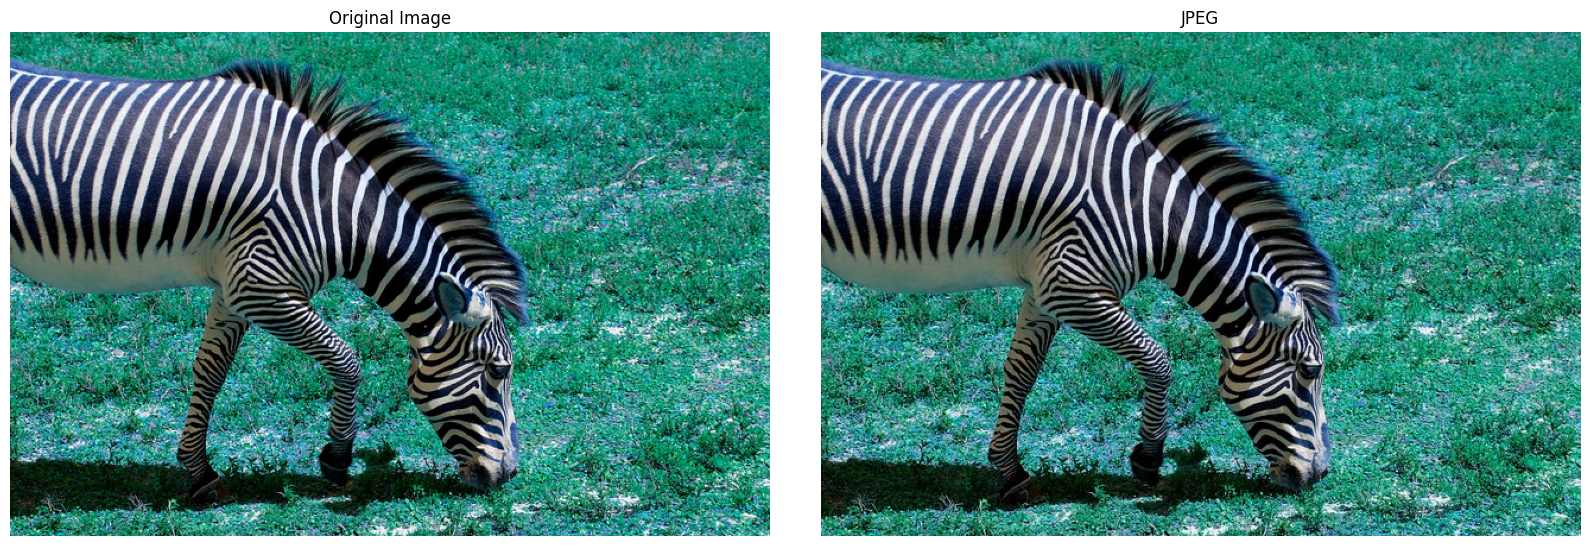

In [36]:
visualize_attack(original, "JPEG")

In [ ]:
visualize_masks(image_paths[0])

In [ ]:
test_attack(image_paths[:1], attack=apply_gaussian_noise, params=[0,0.001])

In [ ]:
def extract_binary_sequence(image_path, grid_size=16, tolerance = 0.02):
    image = cv2.imread(image_path)

    if image is None:
        raise ValueError(f"Could not read image: {image_path}")

    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    height, width = image.shape[:2]

    masks = mask_generator.generate(image)

    count_matrix = np.zeros((height, width), dtype=np.uint16)

    for mask in masks:
        count_matrix += mask["segmentation"].astype(np.uint16)

    binary_matrix = (count_matrix > 0).astype(np.uint8)

    def calculate_grid_means(matrix):
        features = np.zeros((grid_size, grid_size), dtype=np.float64)

        for row in range(grid_size):
            for col in range(grid_size):
                y1 = row * height // grid_size
                y2 = (row + 1) * height // grid_size
                x1 = col * width // grid_size
                x2 = (col + 1) * width // grid_size

                cell = matrix[y1:y2, x1:x2]
                features[row, col] = np.mean(cell)

        return features

    count_features = calculate_grid_means(count_matrix)
    binary_features = calculate_grid_means(binary_matrix)

    def compare_neighbors(features):
        sequence = ""

        # First: horizontal comparisons (left to right)
        for row in range(grid_size):
            for col in range(grid_size - 1):
              difference = features[row, col] - features[row, col + 1]

              if difference > tolerance:
                  sequence += "1"
              elif difference < -tolerance:
                  sequence += "0"
              else:
                  sequence += "0"

                # if features[row, col] < features[row, col + 1]:
                #     sequence += "1"
                # else:
                #     sequence += "0"

        # Then: vertical comparisons (top to bottom)
        for row in range(grid_size - 1):
            for col in range(grid_size):

              difference = features[row, col] - features[row + 1, col]

              if difference > tolerance:
                  sequence += "1"
              elif difference < -tolerance:
                  sequence += "0"
              else:
                  sequence += "0"

              # if features[row, col] < features[row + 1, col]:
              #     sequence += "1"
              # else:
              #     sequence += "0"

        return sequence

    count_sequence = compare_neighbors(count_features)
    binary_sequence = compare_neighbors(binary_features)

    return count_sequence, binary_sequence

In [ ]:
cs, bs = extract_binary_sequence(image_paths[0], grid_size=4)

In [ ]:
cs, bs

In [ ]:
apply_gaussian_noise(image_paths[0], [0,0.001])

In [ ]:
att_cs, att_bs = extract_binary_sequence('/test.jpg', grid_size=4)
att_cs, att_bs

In [ ]:
att_cs == cs

In [ ]:
def visualize_sam_encoding(image_path, grid_size=16):

    image_bgr = cv2.imread(image_path)

    if image_bgr is None:
        raise ValueError(f"Could not read image: {image_path}")

    image = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB)
    height, width = image.shape[:2]

    print("=" * 60)
    print("IMAGE INFORMATION")
    print("=" * 60)
    print(f"Image path: {image_path}")
    print(f"Image size (width x height): {width} x {height}")
    print(f"Image array shape: {image.shape}")
    print(f"Grid size: {grid_size} x {grid_size}")

    # ==========================================
    # 2. Generate SAM masks
    # ==========================================
    masks = mask_generator.generate(image)

    print(f"Number of SAM masks: {len(masks)}")

    # Create a visualization of the regular SAM masks.
    # Each mask is assigned a different random color.
    rng = np.random.default_rng(42)
    mask_visualization = np.zeros_like(image)

    for mask in masks:
        segmentation = mask["segmentation"]
        color = rng.integers(50, 256, size=3, dtype=np.uint8)
        mask_visualization[segmentation] = color

    # ==========================================
    # 3. Create the count matrix and binary matrix
    # ==========================================
    count_matrix = np.zeros((height, width), dtype=np.uint16)

    for mask in masks:
        count_matrix += mask["segmentation"].astype(np.uint16)

    # 1 = covered by at least one mask
    # 0 = not covered by any mask
    binary_matrix = (count_matrix > 0).astype(np.uint8)

    print(f"Mask-count matrix shape: {count_matrix.shape}")
    print(f"Binary matrix shape: {binary_matrix.shape}")
    print(f"Percentage of image covered by masks: "
          f"{np.mean(binary_matrix) * 100:.2f}%")

    # ==========================================
    # 4. Calculate the mean of each grid cell
    # ==========================================
    def calculate_grid_means(matrix):

        features = np.zeros(
            (grid_size, grid_size),
            dtype=np.float64
        )

        for row in range(grid_size):
            for col in range(grid_size):

                y1 = row * height // grid_size
                y2 = (row + 1) * height // grid_size

                x1 = col * width // grid_size
                x2 = (col + 1) * width // grid_size

                cell = matrix[y1:y2, x1:x2]

                features[row, col] = np.mean(cell)

        return features

    count_features = calculate_grid_means(count_matrix)
    binary_features = calculate_grid_means(binary_matrix)

    # ==========================================
    # 5. Convert grid features to binary sequences
    # ==========================================
    def compare_neighbors(features):

        sequence = ""

        # Horizontal comparisons: left -> right
        for row in range(grid_size):
            for col in range(grid_size - 1):

                if features[row, col] < features[row, col + 1]:
                    sequence += "1"
                else:
                    sequence += "0"

        # Vertical comparisons: top -> bottom
        for row in range(grid_size - 1):
            for col in range(grid_size):

                if features[row, col] < features[row + 1, col]:
                    sequence += "1"
                else:
                    sequence += "0"

        return sequence

    count_sequence = compare_neighbors(count_features)
    binary_sequence = compare_neighbors(binary_features)

    # ==========================================
    # 6. Visualize the original image and masks
    # ==========================================
    fig, axes = plt.subplots(
        1, 3,
        figsize=(18, 6),
        constrained_layout=True
    )

    axes[0].imshow(image)
    axes[0].set_title(
        f"Original Image\n{width} x {height} pixels",
        fontsize=12,
        pad=12
    )

    axes[1].imshow(mask_visualization)
    axes[1].set_title(
        f"Regular SAM Masks\n{len(masks)} masks",
        fontsize=12,
        pad=12
    )

    axes[2].imshow(binary_matrix, cmap="gray", vmin=0, vmax=1)
    axes[2].set_title(
        "Binary Coverage Mask\nWhite = covered, Black = uncovered",
        fontsize=12,
        pad=12
    )

    for ax in axes:
        ax.axis("off")

    plt.show()

    # ==========================================
    # Visualize the original image with grid lines
    # ==========================================
    fig, ax = plt.subplots(figsize=(10, 8))

    ax.imshow(image)

    # Draw vertical grid lines
    for col in range(grid_size + 1):
        x = col * width / grid_size - 0.5
        ax.axvline(x=x, color="black", linewidth=0.8)

    # Draw horizontal grid lines
    for row in range(grid_size + 1):
        y = row * height / grid_size - 0.5
        ax.axhline(y=y, color="black", linewidth=0.8)

    # Label each cell by its row and column indices
    ax.set_xticks([
        (col + 0.5) * width / grid_size - 0.5
        for col in range(grid_size)
    ])
    ax.set_yticks([
        (row + 0.5) * height / grid_size - 0.5
        for row in range(grid_size)
    ])

    ax.set_xticklabels(range(grid_size), fontsize=8)
    ax.set_yticklabels(range(grid_size), fontsize=8)

    ax.set_title(
        f"Image Divided into a {grid_size} × {grid_size} Grid\n"
        f"Image dimensions: {width} × {height} pixels",
        fontsize=13,
        pad=14
    )

    ax.set_xlabel("Grid Column", labelpad=8)
    ax.set_ylabel("Grid Row", labelpad=8)

    fig.tight_layout()
    plt.show()

    # ==========================================
    # 7. Visualize the two grid-feature matrices
    # ==========================================
    fig, axes = plt.subplots(
        1, 2,
        figsize=(16, 7),
        constrained_layout=True
    )

    matrices = [
        (count_features, "Mean Mask Count per Grid Cell"),
        (binary_features, "Mean Binary Coverage per Grid Cell")
    ]

    for ax, (features, title) in zip(axes, matrices):

        im = ax.imshow(features, cmap="viridis")
        ax.set_title(title, fontsize=12, pad=12)
        ax.set_xlabel("Grid Column", labelpad=8)
        ax.set_ylabel("Grid Row", labelpad=8)

        ax.set_xticks(np.arange(grid_size))
        ax.set_yticks(np.arange(grid_size))

        # Print each cell's mean value inside the grid
        for row in range(grid_size):
            for col in range(grid_size):

                value = features[row, col]

                ax.text(
                    col,
                    row,
                    f"{value:.2f}",
                    ha="center",
                    va="center",
                    fontsize=7,
                    color="white" if value < features.max() * 0.65
                    else "black"
                )

        fig.colorbar(
            im,
            ax=ax,
            fraction=0.046,
            pad=0.04,
            shrink=0.88
        )

    plt.show()

    # ==========================================
    # 8. Print the numerical matrices
    # ==========================================
    np.set_printoptions(
        precision=3,
        suppress=True,
        linewidth=160
    )

    print("\n" + "=" * 60)
    print("GRID FEATURE MATRICES")
    print("=" * 60)

    print("\n1. Mean mask count per cell:")
    print(count_features)

    print("\n2. Mean binary coverage per cell:")
    print(binary_features)

    # ==========================================
    # 9. Print binary sequences
    # ==========================================
    print("\n" + "=" * 60)
    print("BINARY ENCODING")
    print("=" * 60)

    print(f"\nMask-count sequence ({len(count_sequence)} bits):")
    print(count_sequence)

    print(f"\nBinary-coverage sequence ({len(binary_sequence)} bits):")
    print(binary_sequence)

    # Return results so they can be reused later
    return {
        "image": image,
        "masks": masks,
        "mask_visualization": mask_visualization,
        "count_matrix": count_matrix,
        "binary_matrix": binary_matrix,
        "count_features": count_features,
        "binary_features": binary_features,
        "count_sequence": count_sequence,
        "binary_sequence": binary_sequence,
        "image_width": width,
        "image_height": height,
        "mask_count": len(masks)
    }

In [ ]:
data_dict = visualize_sam_encoding(image_paths[0], grid_size=4)

In [ ]:
attacted_data_dict = visualize_sam_encoding('test.jpg', grid_size=4)

In [ ]:
data_dict["count_features"], attacted_data_dict["count_features"]

In [ ]:
def h5_generator(
    output_path="/content/drive/MyDrive/coco_dataset/",
    images_path="/content/drive/MyDrive/coco_dataset/train2017",
    with_noise=False,
    with_compression=False,
    num_images=500
    ):
  import h5py
  import numpy as np

  image_paths = get_image_paths(images_path)[:num_images]
  OUTPUT_FILE = output_path + f"\
    SAM_outputs_\
    {'with_compression' if with_compression else 'without_compression'}\
    {'with_noise' if with_noise else 'without_noise'}\
    _.h5"

  with h5py.File(OUTPUT_FILE, "a") as h5:
    for i, im in enumerate(image_paths):

      key = f"{i:04d}"

      if key in h5:
          continue

      image = cv2.imread(im)
      if image is None:
          continue

      image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

      with torch.inference_mode():
        if with_noise:
          image = apply_gaussian_noise(image, [0,0.001])
        if with_compression:
          image = apply_jpeg_comp(image, quality=90)
        print("About to generate")
        outputs = mask_generator.generate(image)

      temp_key = f"temp_{key}"
      if temp_key in h5:
        del h5[temp_key]

      group = h5.create_group(temp_key)
      group.attrs["image_path"] = im
      group.attrs["mask_count"] = len(outputs)

      if outputs:
        for field in outputs[0].keys():
            values = np.stack([m[field] for m in outputs])
            group.create_dataset(
              field,
              data=values,
              compression="gzip",
              compression_opts=4
            )

      h5.move(temp_key, key)
      h5.flush()


      del image, outputs

In [ ]:
import h5py
import numpy as np
from pathlib import Path


OUTPUT_FILE = Path("/dataset/SAM_outputs.h5")
if OUTPUT_FILE is None:
    raise FileNotFoundError(
        "SAM_outputs.h5 not found. Checked:\n"
        + "\n".join(f"  - {p}" for p in candidates)
        + "\nIf running in Colab, make sure Google Drive is mounted."
    )

with h5py.File(OUTPUT_FILE, "r") as h5:
    image = h5["0000"]

    masks = image["segmentation"][:]
    boxes = image["bbox"][:]
    areas = image["area"][:]
    iou = image["predicted_iou"][:]
    stability = image["stability_score"][:]

    print("Image Path:", image.attrs["image_path"])
    print("Number of masks:", image.attrs["mask_count"])
    print("Mask shape:", masks.shape)
    print(iou)


In [ ]:
h5_generator()
# from concurrent.futures import ThreadPoolExecutor
# with ThreadPoolExecutor(max_workers=2) as executor:
#     f1 = executor.submit(h5_generator, with_noise=True)
#     f2 = executor.submit(h5_generator, with_compression=True)
